# Практика 2. Наложение и удаление шума (`sar_1.jpg`)

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity, mean_squared_error

np.random.seed(0)
cv2.setRNGSeed(0)   # воспроизводимость шума

## 1. Загрузка изображения

Размер (h, w): (675, 1200) | тип: uint8


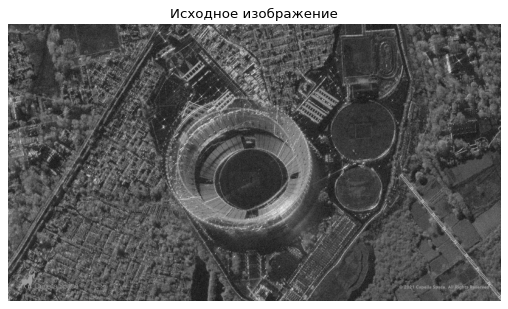

In [2]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Размер (h, w):", image_gray.shape, "| тип:", image_gray.dtype)

plt.figure(figsize=(8, 4.5))
plt.imshow(image_gray, cmap='gray', vmin=0, vmax=255)
plt.title("Исходное изображение")
plt.axis('off')
plt.show()

## 2. Наложение шума

Шум хранится в `uint8` и накладывается через `cv2.add`, поэтому шумовые составляющие — неотрицательные элементы (значения ниже нуля при генерации обрезаются до 0, результат сложения обрезается сверху до 255).

- **Гауссов шум:** `cv2.randn`, mean = 0, σ = 25.
- **Постоянный (равномерный) шум:** плотность $p(z) = \frac{1}{b-a}$ при $a \le z \le b$; `cv2.randu`, $a = 0$, $b = 50$ (уровни шума подобраны так, чтобы стандартное отклонение у обоих шумов было примерно одинаковым, ≈ 14–15).

Диапазон шума: gauss [0, 116], uniform [0, 49]
Среднее значение шума (положительное смещение яркости): gauss 9.98, uniform 24.54

Зашумлённое vs исходное          MSE      SSIM
Гауссов шум                   312.38    0.6948
Постоянный шум                809.78    0.6710


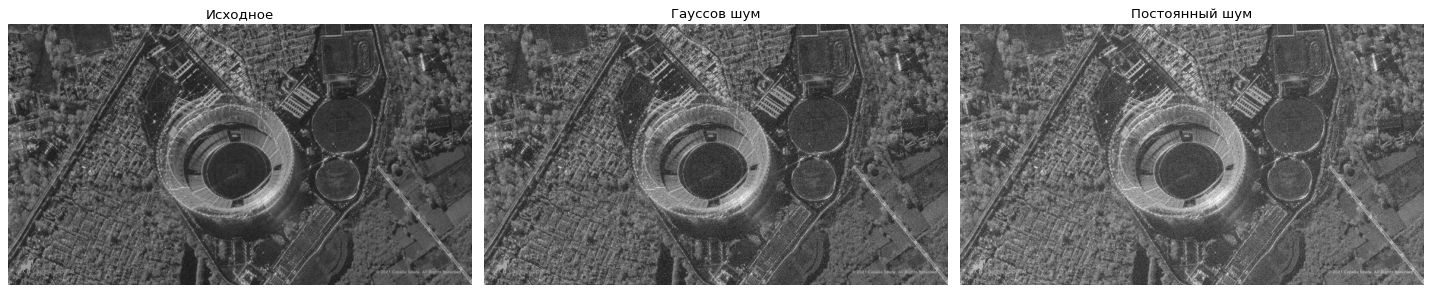

In [3]:
def mse_ssim(ref, img):
    return (mean_squared_error(ref, img),
            structural_similarity(ref, img, data_range=255))

# Гауссов шум
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, 0, 25)
image_noise_gauss = cv2.add(image_gray, noise_gauss)

# Постоянный (равномерный) шум
noise_uniform = np.zeros(image_gray.shape, np.uint8)
cv2.randu(noise_uniform, 0, 50)
image_noise_uniform = cv2.add(image_gray, noise_uniform)

print("Диапазон шума: gauss [{}, {}], uniform [{}, {}]".format(
    noise_gauss.min(), noise_gauss.max(), noise_uniform.min(), noise_uniform.max()))

print("Среднее значение шума (положительное смещение яркости): gauss {:.2f}, uniform {:.2f}".format(
    noise_gauss.mean(), noise_uniform.mean()))

print("\n{:<26}{:>10}{:>10}".format("Зашумлённое vs исходное", "MSE", "SSIM"))
for name, im in [("Гауссов шум", image_noise_gauss), ("Постоянный шум", image_noise_uniform)]:
    m, s = mse_ssim(image_gray, im)
    print("{:<26}{:>10.2f}{:>10.4f}".format(name, m, s))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, im, t in zip(axes, [image_gray, image_noise_gauss, image_noise_uniform],
                     ["Исходное", "Гауссов шум", "Постоянный шум"]):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Фильтрация с различными параметрами

Каждый фильтр запускается с набором параметров. Качество оценивается относительно **незашумлённого** изображения: чем меньше MSE и чем больше SSIM, тем лучше.

In [4]:
def make_configs():
    cfgs = []
    for k in [3, 5, 7, 9]:
        cfgs.append(("Медианный", "ksize={}".format(k),
                     lambda im, k=k: cv2.medianBlur(im, k)))
    for k, sg in [(3, 0.5), (3, 0), (5, 1.0), (5, 0), (7, 0)]:
        cfgs.append(("Гаусса", "ksize=({0},{0}), sigma={1}".format(k, sg),
                     lambda im, k=k, sg=sg: cv2.GaussianBlur(im, (k, k), sg)))
    for d, sc, ss in [(5, 15, 15), (5, 25, 25), (5, 40, 40), (9, 25, 25), (9, 50, 50), (15, 50, 50)]:
        cfgs.append(("Билатеральный", "d={}, sigmaColor={}, sigmaSpace={}".format(d, sc, ss),
                     lambda im, d=d, sc=sc, ss=ss: cv2.bilateralFilter(im, d, sc, ss)))
    for h, t, s in [(5, 7, 21), (10, 7, 21), (15, 7, 21), (20, 7, 21), (10, 5, 15), (10, 3, 11)]:
        cfgs.append(("Нелокальных средних", "h={}, template={}, search={}".format(h, t, s),
                     lambda im, h=h, t=t, s=s: cv2.fastNlMeansDenoising(im, None, h, t, s)))
    return cfgs


def run_filters(noisy):
    results = []
    for fname, params, fn in make_configs():
        out = fn(noisy)
        m, s = mse_ssim(image_gray, out)
        results.append({"filter": fname, "params": params, "mse": m, "ssim": s, "image": out})
    return results


def print_table(results):
    print("{:<22}{:<42}{:>10}{:>10}".format("Фильтр", "Параметры", "MSE", "SSIM"))
    prev = None
    for r in results:
        if prev is not None and r["filter"] != prev:
            print()
        prev = r["filter"]
        print("{:<22}{:<42}{:>10.2f}{:>10.4f}".format(r["filter"], r["params"], r["mse"], r["ssim"]))

### 3.1. Гауссов шум

In [5]:
results_gauss = run_filters(image_noise_gauss)
print_table(results_gauss)

Фильтр                Параметры                                        MSE      SSIM
Медианный             ksize=3                                       182.84    0.7503
Медианный             ksize=5                                       253.55    0.6104
Медианный             ksize=7                                       310.87    0.5084
Медианный             ksize=9                                       360.61    0.4307

Гаусса                ksize=(3,3), sigma=0.5                        202.20    0.7962
Гаусса                ksize=(3,3), sigma=0                          193.63    0.8091
Гаусса                ksize=(5,5), sigma=1.0                        217.68    0.7669
Гаусса                ksize=(5,5), sigma=0                          225.59    0.7522
Гаусса                ksize=(7,7), sigma=0                          271.41    0.6686

Билатеральный         d=5, sigmaColor=15, sigmaSpace=15             229.77    0.7383
Билатеральный         d=5, sigmaColor=25, sigmaSpace=25        

### 3.2. Постоянный (равномерный) шум

In [6]:
results_uniform = run_filters(image_noise_uniform)
print_table(results_uniform)

Фильтр                Параметры                                        MSE      SSIM
Медианный             ksize=3                                       735.64    0.6845
Медианный             ksize=5                                       785.70    0.5662
Медианный             ksize=7                                       829.89    0.4755
Медианный             ksize=9                                       870.85    0.4038

Гаусса                ksize=(3,3), sigma=0.5                        702.65    0.7694
Гаусса                ksize=(3,3), sigma=0                          696.38    0.7813
Гаусса                ksize=(5,5), sigma=1.0                        719.77    0.7400
Гаусса                ksize=(5,5), sigma=0                          727.73    0.7259
Гаусса                ksize=(7,7), sigma=0                          773.59    0.6446

Билатеральный         d=5, sigmaColor=15, sigmaSpace=15             701.27    0.7444
Билатеральный         d=5, sigmaColor=25, sigmaSpace=25        

## 4. Лучший вариант каждого фильтра и выбор лучшего фильтра

=== Гауссов шум ===
Фильтр (лучшие параметры по MSE)                                                 MSE      SSIM
Без фильтрации                                                      312.38    0.6948
Билатеральный         d=5, sigmaColor=40, sigmaSpace=40             173.65    0.7869
Медианный             ksize=3                                       182.84    0.7503
Гаусса                ksize=(3,3), sigma=0                          193.63    0.8091
Нелокальных средних   h=15, template=7, search=21                   200.99    0.7332
Лучший по MSE : Билатеральный (d=5, sigmaColor=40, sigmaSpace=40)
Лучший по SSIM: Гаусса (ksize=(3,3), sigma=0)

=== Постоянный шум ===
Фильтр (лучшие параметры по MSE)                                                 MSE      SSIM
Без фильтрации                                                      809.78    0.6710
Билатеральный         d=5, sigmaColor=25, sigmaSpace=25             664.92    0.7809
Нелокальных средних   h=15, template=7, search=21          

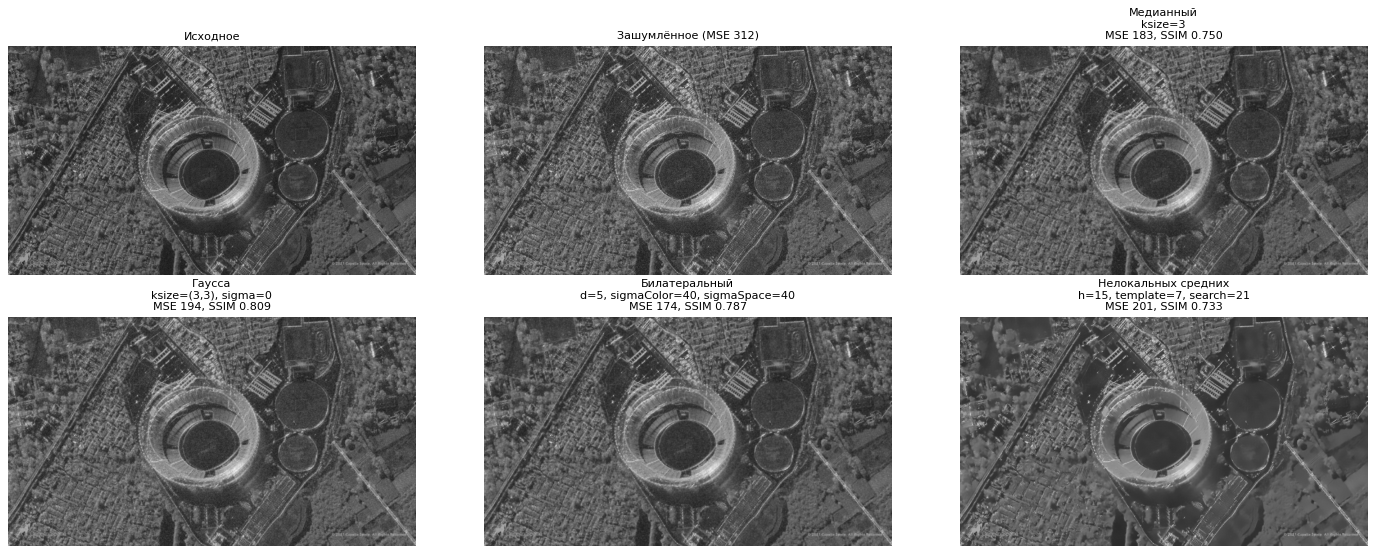

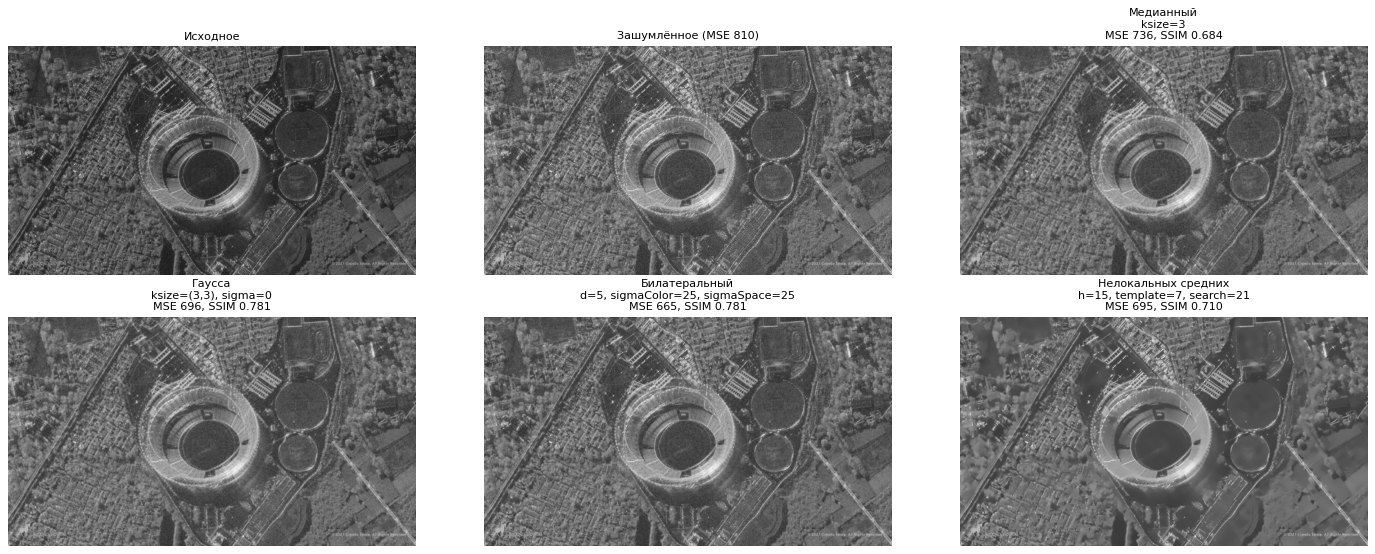

In [7]:
def best_per_filter(results):
    best = {}
    for r in results:
        if r["filter"] not in best or r["mse"] < best[r["filter"]]["mse"]:
            best[r["filter"]] = r
    return list(best.values())


def report(title, noisy, results):
    best = best_per_filter(results)
    best_sorted = sorted(best, key=lambda r: r["mse"])
    m0, s0 = mse_ssim(image_gray, noisy)
    print("=== {} ===".format(title))
    print("{:<22}{:<42}{:>10}{:>10}".format("Фильтр (лучшие параметры по MSE)", "", "MSE", "SSIM"))
    print("{:<22}{:<42}{:>10.2f}{:>10.4f}".format("Без фильтрации", "", m0, s0))
    for r in best_sorted:
        print("{:<22}{:<42}{:>10.2f}{:>10.4f}".format(r["filter"], r["params"], r["mse"], r["ssim"]))
    by_ssim = max(best, key=lambda r: r["ssim"])
    print("Лучший по MSE : {} ({})".format(best_sorted[0]["filter"], best_sorted[0]["params"]))
    print("Лучший по SSIM: {} ({})\n".format(by_ssim["filter"], by_ssim["params"]))

    fig, axes = plt.subplots(2, 3, figsize=(18, 7))
    shown = [("Исходное", image_gray), ("Зашумлённое (MSE {:.0f})".format(m0), noisy)]
    shown += [("{}\n{}\nMSE {:.0f}, SSIM {:.3f}".format(r["filter"], r["params"], r["mse"], r["ssim"]), r["image"])
              for r in best]
    for ax, (t, im) in zip(axes.ravel(), shown):
        ax.imshow(im, cmap='gray', vmin=0, vmax=255); ax.set_title(t, fontsize=10); ax.axis('off')
    plt.tight_layout(); plt.show()


report("Гауссов шум", image_noise_gauss, results_gauss)
report("Постоянный шум", image_noise_uniform, results_uniform)

## Вывод

**Лучший фильтр по MSE — билатеральный, и для гауссова, и для постоянного шума.** Он берёт малое окно (`d=5`) и умеренную `sigmaColor` (≈ 25–40):

| Шум | MSE без фильтра | MSE билатерального | SSIM билатерального |
|---|---|---|---|
| Гауссов | 312.38 | 173.65 | 0.787 |
| Постоянный | 809.78 | 664.92 | 0.781 |

- **Фильтр Гаусса** (3×3) даёт лучший SSIM (на постоянном шуме практически вровень с билатеральным), но по MSE немного проигрывает.
- **Медианный** (ksize = 3) на гауссовом шуме почти не уступает по MSE, но заметно хуже по SSIM; на постоянном шуме он слабее остальных.
- **Нелокальных средних** на этом снимке выигрыша не дал: лучший результат при `h ≈ 15`, при `h = 5` он почти не меняет изображение, при `h = 20` начинает сглаживать детали.
- Увеличение окна и сигм **у всех фильтров ухудшает** результат: на SAR-снимке много мелких деталей, сильное сглаживание их стирает.
- **Оговорка про MSE.** Шум неотрицательный, поэтому он поднимает среднюю яркость (≈ 10 для гауссова и ≈ 24.5 для постоянного). Сглаживающие фильтры это смещение не убирают, и MSE не может опуститься ниже примерно квадрата смещения (≈ 100 и ≈ 600). Из-за этого абсолютные значения MSE для постоянного шума выше, а сравнивать фильтры лучше между собой, а не с нулём.